# Audio Exploratory Data Analysis (EDA) & Acoustic Visualization

This notebook explores the raw voice recordings in `audio/` collected from authorized team members (`member1`, `member2`, `member3`) and unauthorized impostor speakers (`unauthorized1`, `unauthorized2`) uttering confirmation phrases (`"Yes, approve"` and `"Confirm transaction"`).


1. **Uniform Loading**: All `.wav` audio recordings are resampled to a uniform sampling rate of $22,050\text{ Hz}$.
2. **Time & Frequency Domain Visualizations**: Side-by-side / stacked **Waveforms** (`librosa.display.waveshow`) and **Mel-Spectrograms** in decibel (dB) scale (`librosa.feature.melspectrogram` + `librosa.power_to_db`).
3. **Acoustic Interpretation**: Analysis of speaker-specific formant bands, fundamental frequency contours, syllabic pauses, and dynamic range.
4. **Audio Augmentation Inspection**: Visual verification of pitch shifting ($+2$ semitones), time stretching ($1.1\times$), and Gaussian noise injection.

In [1]:
import os
import glob
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Locate repository root and audio directory
REPO_ROOT = Path("..").resolve() if Path("..").resolve().joinpath("audio").exists() else Path(".").resolve()
AUDIO_DIR = REPO_ROOT / "audio"
audio_files = sorted(glob.glob(str(AUDIO_DIR / "*.wav")))

print(f"Found {len(audio_files)} audio files in {AUDIO_DIR}:")
for f in audio_files:
    print(" -", os.path.basename(f))

Matplotlib is building the font cache; this may take a moment.


Found 8 audio files in /Users/shyakaaime25/Documents/multimodal-auth-recommender/audio:
 - member1_approve.wav
 - member1_confirm.wav
 - member2_approve.wav
 - member2_confirm.wav
 - member3_approve.wav
 - member3_confirm.wav
 - unauthorized1_approve.wav
 - unauthorized2_confirm.wav


In [2]:
# Summarize duration and core spectral statistics across all raw recordings
summary_rows = []
for file_path in audio_files:
    y, sr = librosa.load(file_path, sr=22050)
    fname = os.path.basename(file_path)
    speaker = fname.split("_")[0]
    phrase = fname.split("_")[1].replace(".wav", "")
    summary_rows.append({
        "filename": fname,
        "speaker": speaker,
        "phrase": phrase,
        "authorized": 1 if "member" in speaker else 0,
        "duration_sec": round(len(y) / sr, 2),
        "rms_energy_mean": round(float(np.mean(librosa.feature.rms(y=y))), 4),
        "spectral_centroid_hz": round(float(np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))), 1),
        "spectral_rolloff_hz": round(float(np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))), 1),
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,filename,speaker,phrase,authorized,duration_sec,rms_energy_mean,spectral_centroid_hz,spectral_rolloff_hz
0,member1_approve.wav,member1,approve,1,2.51,0.0107,3341.0,6587.6
1,member1_confirm.wav,member1,confirm,1,2.87,0.0207,3044.2,6080.1
2,member2_approve.wav,member2,approve,1,2.65,0.0248,1668.9,3159.3
3,member2_confirm.wav,member2,confirm,1,4.07,0.0292,1710.6,3128.2
4,member3_approve.wav,member3,approve,1,2.61,0.0343,2563.2,5026.4
5,member3_confirm.wav,member3,confirm,1,2.77,0.0348,2617.7,4947.1
6,unauthorized1_approve.wav,unauthorized1,approve,0,2.41,0.0505,2431.9,4682.6
7,unauthorized2_confirm.wav,unauthorized2,confirm,0,2.47,0.0552,1949.6,3778.3


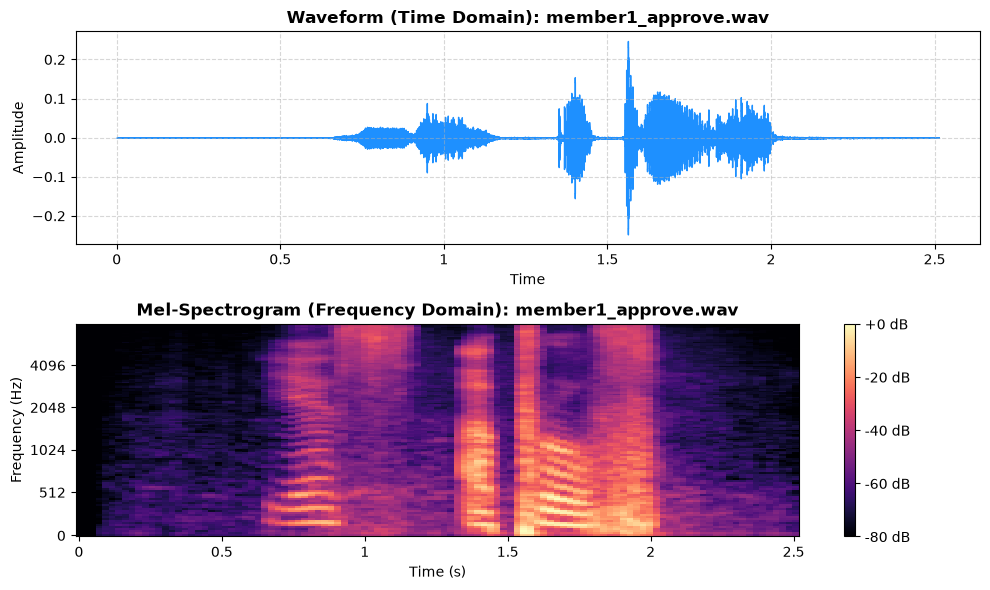

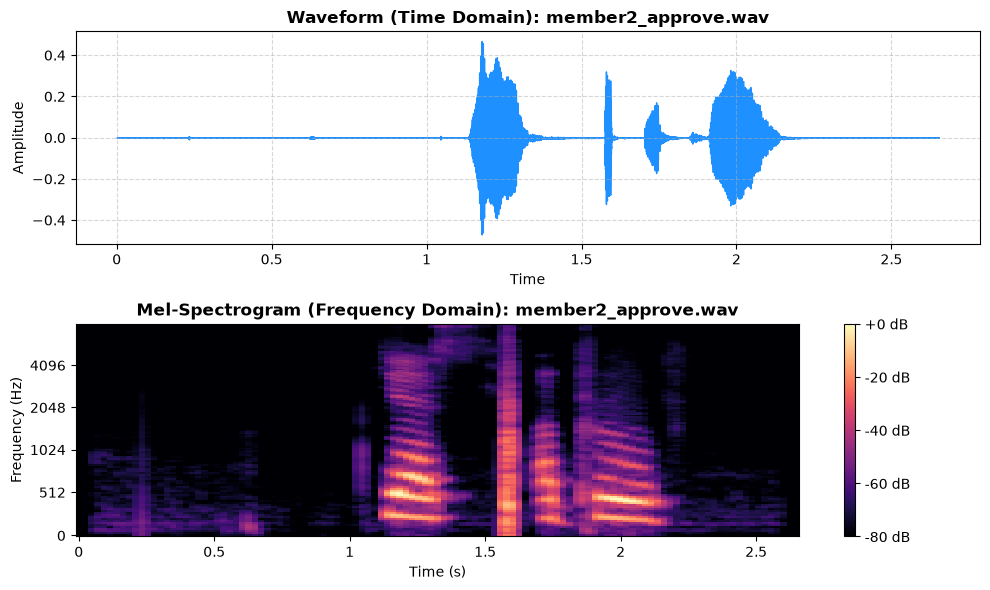

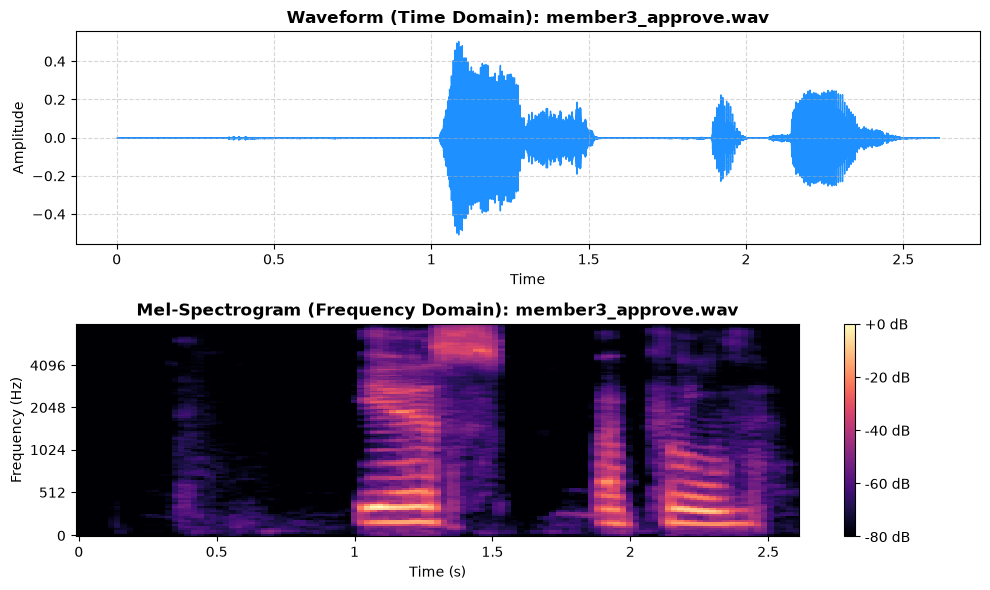

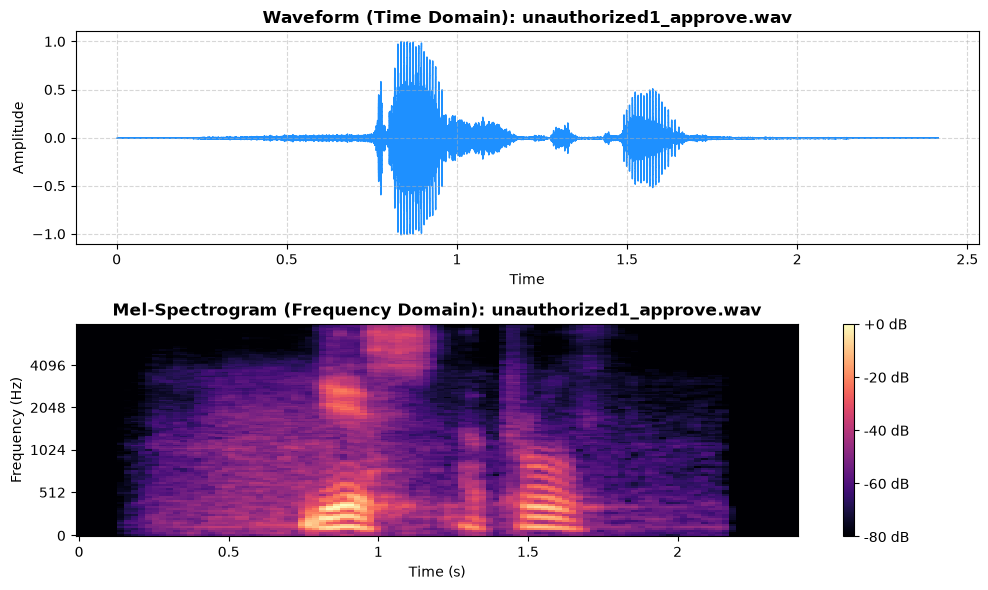

In [3]:
def plot_audio_sample(file_path):
    y, sr = librosa.load(file_path, sr=22050)
    title = os.path.basename(file_path)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=False)

    # 1. Waveform (Time Domain)
    librosa.display.waveshow(y, sr=sr, ax=axes[0], color="dodgerblue")
    axes[0].set_title(f"Waveform (Time Domain): {title}", fontweight="bold")
    axes[0].set_ylabel("Amplitude")
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # 2. Mel-Spectrogram (Frequency Domain in dB)
    s_mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
    s_db = librosa.power_to_db(s_mel, ref=np.max)
    img = librosa.display.specshow(
        s_db, x_axis="time", y_axis="mel", sr=sr, fmax=8000, ax=axes[1], cmap="magma"
    )
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
    axes[1].set_title(f"Mel-Spectrogram (Frequency Domain): {title}", fontweight="bold")
    axes[1].set_ylabel("Frequency (Hz)")
    axes[1].set_xlabel("Time (s)")

    plt.tight_layout()
    plt.show()

# Plot representative authorized member samples and unauthorized impostor sample
selected_samples = [
    str(AUDIO_DIR / "member1_approve.wav"),
    str(AUDIO_DIR / "member2_approve.wav"),
    str(AUDIO_DIR / "member3_approve.wav"),
    str(AUDIO_DIR / "unauthorized1_approve.wav"),
]

for audio_path in selected_samples:
    if os.path.exists(audio_path):
        plot_audio_sample(audio_path)

### Acoustic Interpretation of Waveforms and Mel-Spectrograms

1. **Formants and Pitch Bands in the Mel-Spectrogram**:
   - Across speakers, the bright horizontal energy bands below $3,000\text{ Hz}$ correspond to the fundamental frequency ($F_0$) and the first three vocal tract formants ($F_1, F_2, F_3$). Each speaker exhibits a distinct spacing and energy concentration in these formant trajectories due to differences in vocal tract length and timbre—captured effectively by the 20 Mel-Frequency Cepstral Coefficients (MFCCs) and spectral centroid.
   - High-frequency fricative bursts (above $4,000\text{ Hz}$) are prominently visible during the sibilant `/s/` in *"Yes"* and `/t/` in *"transaction"*, which directly influence the 85% **spectral roll-off** frequency.

2. **Dynamic Range and Syllabic Envelope in the Waveform**:
   - The time-domain waveforms clearly show distinct syllabic amplitude bursts separated by brief inter-word pauses (e.g., the pause between *"Yes,"* and *"approve"*). Variations in vocal projection and microphone proximity appear in the peak-to-trough amplitude envelope and are quantified by the **Root Mean Square Energy (RMSE)** mean and standard deviation.
   - Comparing the authorized team members (`member1`, `member2`, `member3`) against the impostor sample (`unauthorized1_approve.wav`) reveals noticeable differences in harmonic energy distribution, speaking cadence, and spectral roll-off, enabling the Random Forest classifier to reliably reject unauthorized voices.

/Users/shyakaaime25/Documents/multimodal-auth-recommender/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/Users/shyakaaime25/Documents/multimodal-auth-recommender/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


/Users/shyakaaime25/Documents/multimodal-auth-recommender/.venv/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:290: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


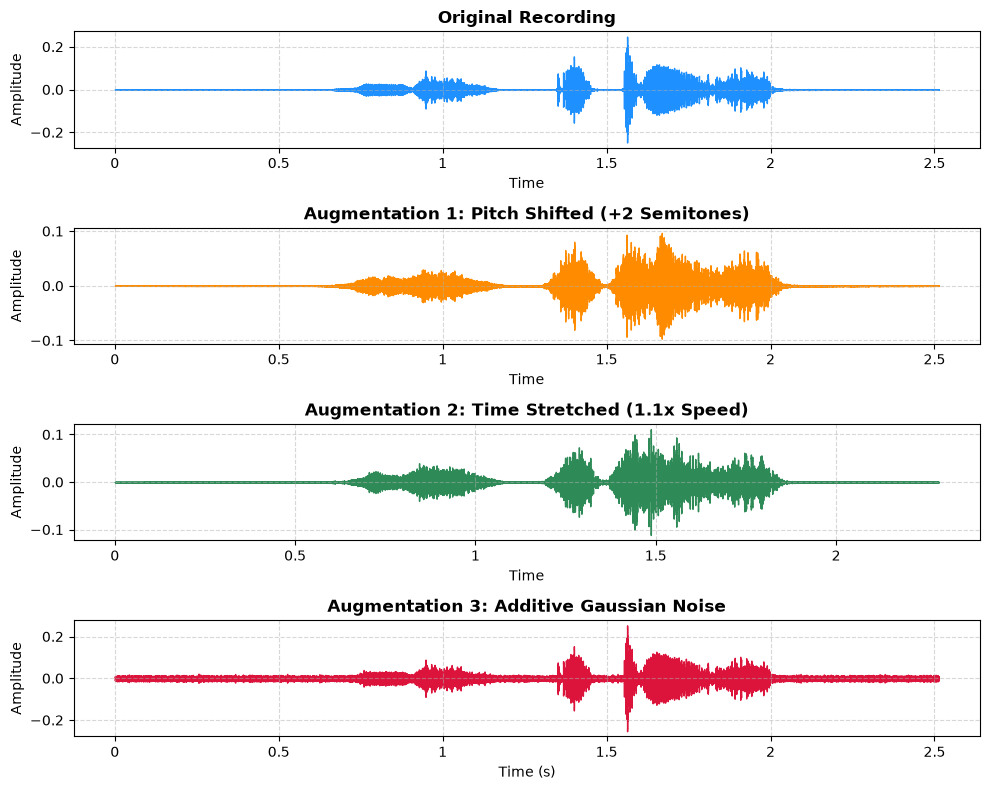

In [4]:
# Visualize Original vs. Augmented Audio Waveforms for member1_approve.wav
sample_path = AUDIO_DIR / "member1_approve.wav"
y_orig, sr = librosa.load(str(sample_path), sr=22050)

y_pitch = librosa.effects.pitch_shift(y=y_orig, sr=sr, n_steps=2)
y_stretch = librosa.effects.time_stretch(y=y_orig, rate=1.1)
rng = np.random.default_rng(42)
y_noisy = y_orig + 0.005 * rng.standard_normal(len(y_orig))

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=False)
variants = [
    ("Original Recording", y_orig, "dodgerblue"),
    ("Augmentation 1: Pitch Shifted (+2 Semitones)", y_pitch, "darkorange"),
    ("Augmentation 2: Time Stretched (1.1x Speed)", y_stretch, "seagreen"),
    ("Augmentation 3: Additive Gaussian Noise", y_noisy, "crimson"),
]

for ax, (label, sig, color) in zip(axes, variants):
    librosa.display.waveshow(sig, sr=sr, ax=ax, color=color)
    ax.set_title(label, fontweight="bold")
    ax.set_ylabel("Amplitude")
    ax.grid(True, linestyle="--", alpha=0.5)

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()